# Segmentación de suelo transitable con Graph Cut


| Método | Modelo de color | Corte |
|---|---|---|
| **GrabCut** (`cv2.grabCut`) | GMM inicializado con semillas y zona incierta | Interno de OpenCV |
| **PyMaxflow** (propio) | Histograma 3D entrenado **solo con semillas** | s-t min-cut con energía propia |

Evalúa los mundos `maze` y `depot` usando solo las imágenes de `datos/`. **No necesita ROS, Gazebo ni los rosbags.**

Al terminar genera, dentro de `resultados/`:

- `metricas_por_frame.csv` y `resumen.csv`
- `barrido_lambda.csv`
- `figuras/iou_por_frame.png` y `figuras/mapas_error.png`
- `videos/comparacion_<mundo>.mp4` y `videos/errores_<mundo>.mp4`

## 1. Configuración

In [1]:
import importlib
import shutil
import subprocess
import sys
from pathlib import Path

import cv2
import maxflow
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "segmentacion.py").exists():
    candidatos = [p.parent for p in RAIZ.rglob("segmentacion.py") if (p.parent / "datos").exists()]
    if not candidatos:
        raise FileNotFoundError("Abre el notebook desde la carpeta graph_cut_suelo_demo")
    RAIZ = candidatos[0]

sys.path.insert(0, str(RAIZ))
import segmentacion as seg
importlib.reload(seg)

MUNDOS = ["maze", "depot"]
DIR_DATOS = RAIZ / "datos"
DIR_RESULTADOS = RAIZ / "resultados"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_VIDEOS = DIR_RESULTADOS / "videos"
for carpeta in (DIR_FIGURAS, DIR_VIDEOS):
    carpeta.mkdir(parents=True, exist_ok=True)

TAM_PROCESO = (160, 120)
TAM_PANEL = (320, 240)
FPS_VIDEO = 30
SEMILLA = 0

COLOR_GRABCUT = "#eb6834"
COLOR_MAXFLOW = "#2a78d6"
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.edgecolor": "#c3c2b7", "font.size": 11,
})

print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__} | NumPy {np.__version__} | PyMaxflow {maxflow.__version__}")
print("ROS cargado:", any(m == "rclpy" or m.startswith("rclpy.") for m in sys.modules))

Python 3.10.13 | OpenCV 5.1.0 | NumPy 2.2.6 | PyMaxflow 1.3.2
ROS cargado: False


## 2. Datos

Cada mundo tiene sus pares en `datos/<mundo>/rgb` y `datos/<mundo>/gt`. Una imagen RGB y su ground truth tienen **el mismo nombre** (el timestamp de la simulación). En el ground truth, `1` es suelo y `0` es todo lo demás.

maze: 886 pares | RGB (240, 320, 3) | GT (240, 320) | valores GT [0, 1]
depot: 527 pares | RGB (240, 320, 3) | GT (240, 320) | valores GT [0, 1]


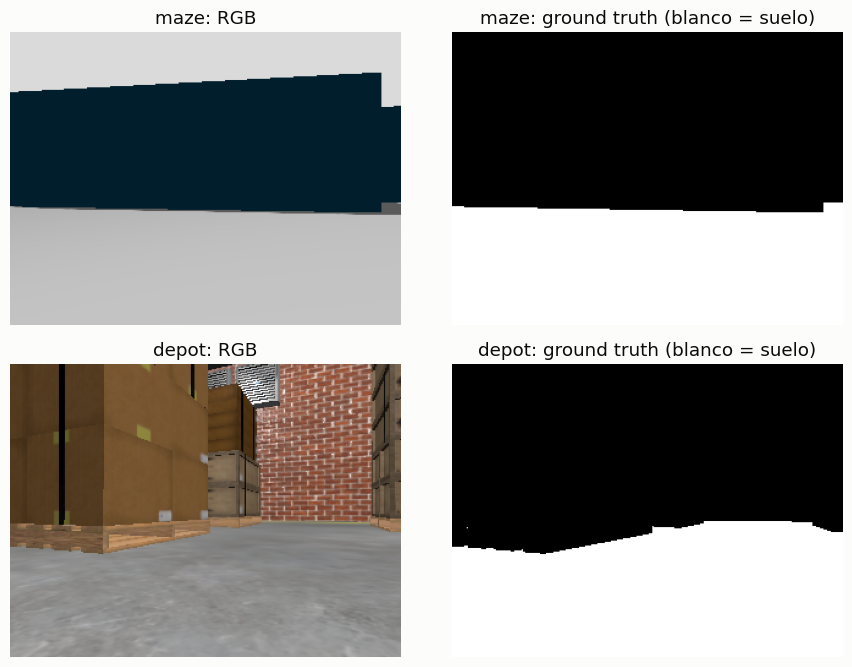

In [2]:
stamps_por_mundo = {}
for mundo in MUNDOS:
    stamps_rgb = {p.stem for p in (DIR_DATOS / mundo / "rgb").glob("*.png")}
    stamps_gt = {p.stem for p in (DIR_DATOS / mundo / "gt").glob("*.png")}
    stamps = sorted(stamps_rgb & stamps_gt)
    if not stamps or stamps_rgb != stamps_gt:
        raise RuntimeError(f"{mundo}: pares incompletos ({len(stamps_rgb)} RGB, {len(stamps_gt)} GT, {len(stamps)} comunes)")
    stamps_por_mundo[mundo] = stamps

def leer_par(mundo, stamp):
    rgb = cv2.imread(str(DIR_DATOS / mundo / "rgb" / f"{stamp}.png"))
    gt = cv2.imread(str(DIR_DATOS / mundo / "gt" / f"{stamp}.png"), cv2.IMREAD_UNCHANGED)
    if rgb is None or gt is None:
        raise IOError(f"No se pudo leer el par {mundo}/{stamp}")
    return rgb, gt

fig, ax = plt.subplots(len(MUNDOS), 2, figsize=(9, 3.4 * len(MUNDOS)))
for fila, mundo in enumerate(MUNDOS):
    stamps = stamps_por_mundo[mundo]
    rgb, gt = leer_par(mundo, stamps[len(stamps) // 2])
    print(f"{mundo}: {len(stamps)} pares | RGB {rgb.shape} | GT {gt.shape} | valores GT {np.unique(gt).tolist()}")
    ax[fila, 0].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)); ax[fila, 0].set_title(f"{mundo}: RGB")
    ax[fila, 1].imshow(gt, cmap="gray", vmin=0, vmax=1); ax[fila, 1].set_title(f"{mundo}: ground truth (blanco = suelo)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 3. El método con PyMaxflow

Se busca la etiqueta $L_p$ (suelo o fondo) de cada píxel que minimiza:

$$E(L)=\sum_p D_p(L_p)+\lambda\sum_{(p,q)\in\mathcal N} w_{pq}\,[L_p\neq L_q]$$

- **Término de datos:** $D_p(c)=-\log P(I_p\mid c)$, con un histograma BGR 3D de 16 bins por canal, suavizado con $\sigma=1$.
- **Término de suavidad:** $w_{pq}=e^{-\beta\|I_p-I_q\|^2}$, con vecindad 4. Cortar es caro entre píxeles parecidos y barato en un borde.
- **Semillas automáticas:** un trapecio frente al robot es suelo y el 28 % superior de la imagen es fondo.

**La decisión clave:** los modelos se entrenan **solo con las semillas**. En GrabCut, la zona incierta tiene que empezar asignada a una clase y contamina su modelo de color. La implementación está en `segmentacion.py`.

## 4. Segmentar y medir todos los frames

In [3]:
def metricas(pred, gt):
    tp = int(np.sum(pred & gt))
    fp = int(np.sum(pred & ~gt))
    fn = int(np.sum(~pred & gt))
    iou = tp / (tp + fp + fn) if tp + fp + fn else 1.0
    precision = tp / (tp + fp) if tp + fp else 1.0
    recall = tp / (tp + fn) if tp + fn else 1.0
    return iou, precision, recall

def preparar(mundo, stamp):
    rgb, gt = leer_par(mundo, stamp)
    frame = cv2.resize(rgb, TAM_PROCESO)
    gt_chico = cv2.resize(gt, TAM_PROCESO, interpolation=cv2.INTER_NEAREST) == 1
    return rgb, frame, gt_chico

filas, mascaras_gc, mascaras_mf = [], {}, {}

for mundo in MUNDOS:
    cv2.setRNGSeed(SEMILLA)   # GrabCut inicializa sus GMM con k-means aleatorio
    for stamp in stamps_por_mundo[mundo]:
        _, frame, gt_chico = preparar(mundo, stamp)

        _, mask_gc, _, _, ms_gc = seg.procesar_graph_cuts(frame)
        _, mask_mf, _, _, ms_mf = seg.procesar_graph_cuts_2(frame)
        pred_gc, pred_mf = mask_gc > 0, mask_mf > 0
        mascaras_gc[mundo, stamp], mascaras_mf[mundo, stamp] = pred_gc, pred_mf

        for metodo, pred, ms in (("GrabCut", pred_gc, ms_gc), ("PyMaxflow", pred_mf, ms_mf)):
            iou, precision, recall = metricas(pred, gt_chico)
            filas.append({"mundo": mundo, "stamp": stamp, "metodo": metodo, "iou": iou,
                          "precision": precision, "recall": recall, "ms": ms})

df = pd.DataFrame(filas)
df.to_csv(DIR_RESULTADOS / "metricas_por_frame.csv", index=False)
print(df.groupby("mundo")["stamp"].nunique().loc[MUNDOS].to_string())
print(f"Filas: {len(df)}")

mundo
maze     886
depot    527
Filas: 2826


## 5. Resultados

In [4]:
resumen = df.groupby(["mundo", "metodo"]).agg(
    frames=("stamp", "nunique"),
    iou_media=("iou", "mean"), iou_mediana=("iou", "median"), iou_min=("iou", "min"),
    precision=("precision", "mean"), recall=("recall", "mean"),
    ms_mediana=("ms", "median"), ms_p95=("ms", lambda x: x.quantile(0.95)),
)
resumen["fps_mediana"] = 1000 / resumen["ms_mediana"]
resumen = resumen.loc[[(m, k) for m in MUNDOS for k in ("GrabCut", "PyMaxflow")]]
resumen.to_csv(DIR_RESULTADOS / "resumen.csv")
resumen.round(4)

frames  iou_media  iou_mediana  iou_min  precision  recall  \
mundo metodo                                                                  
maze  GrabCut       886     0.5379       0.5327   0.4375     0.9999  0.5379   
      PyMaxflow     886     0.9563       0.9771   0.8618     0.9998  0.9565   
depot GrabCut       527     0.7625       0.8836   0.1917     0.9996  0.7628   
      PyMaxflow     527     0.9891       0.9899   0.9429     0.9916  0.9975   

                 ms_mediana   ms_p95  fps_mediana  
mundo metodo                                       
maze  GrabCut       10.9835  13.3842      91.0459  
      PyMaxflow      2.7781   3.3895     359.9643  
depot GrabCut       21.0955  35.2192      47.4034  
      PyMaxflow      2.9960   3.5250     333.7820

### IoU a lo largo del recorrido

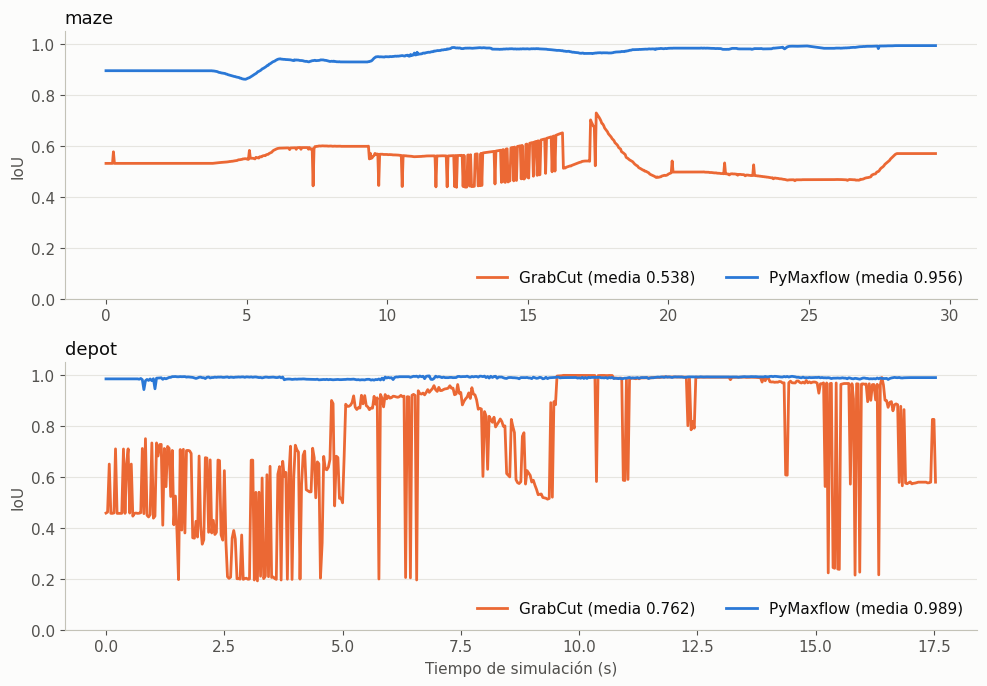

In [5]:
fig, axes = plt.subplots(len(MUNDOS), 1, figsize=(10, 3.5 * len(MUNDOS)), sharey=True)

for ax, mundo in zip(axes, MUNDOS):
    d_mundo = df[df["mundo"] == mundo]
    t0 = int(stamps_por_mundo[mundo][0]) / 1e9
    for metodo, color in (("GrabCut", COLOR_GRABCUT), ("PyMaxflow", COLOR_MAXFLOW)):
        d = d_mundo[d_mundo["metodo"] == metodo]
        t = d["stamp"].astype(np.int64).to_numpy() / 1e9 - t0
        ax.plot(t, d["iou"], color=color, linewidth=2, label=f"{metodo} (media {d['iou'].mean():.3f})")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("IoU")
    ax.set_title(mundo, loc="left", fontsize=13)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False, ncol=2)

axes[-1].set_xlabel("Tiempo de simulación (s)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "iou_por_frame.png", dpi=150)
plt.show()

### Mapas de error

**Verde:** suelo detectado (TP). **Azul:** suelo perdido (FN). **Rojo:** obstáculo marcado como suelo (FP), el error peligroso para el robot.

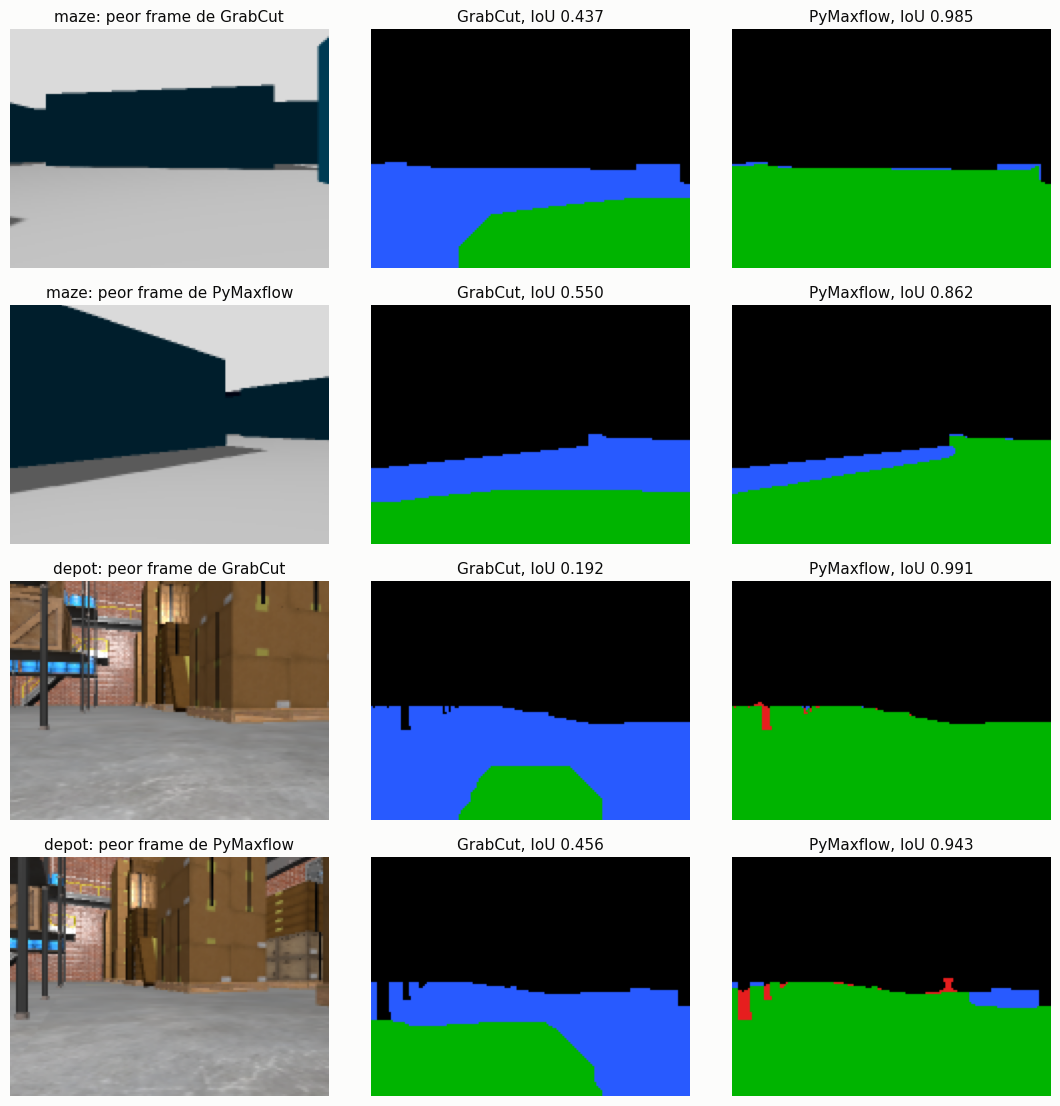

In [6]:
def mapa_errores(pred, gt):
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[pred & gt] = (0, 180, 0)
    errores[~pred & gt] = (40, 90, 255)
    errores[pred & ~gt] = (230, 30, 30)
    return errores

iou_por_metodo = {
    (mundo, metodo): df[(df["mundo"] == mundo) & (df["metodo"] == metodo)].set_index("stamp")["iou"]
    for mundo in MUNDOS for metodo in ("GrabCut", "PyMaxflow")
}
casos = []
for mundo in MUNDOS:
    casos.append((mundo, f"{mundo}: peor frame de GrabCut", iou_por_metodo[mundo, "GrabCut"].idxmin()))
    casos.append((mundo, f"{mundo}: peor frame de PyMaxflow", iou_por_metodo[mundo, "PyMaxflow"].idxmin()))

fig, ax = plt.subplots(len(casos), 3, figsize=(11, 2.8 * len(casos)))
for fila, (mundo, nombre, stamp) in enumerate(casos):
    _, frame, gt_chico = preparar(mundo, stamp)
    ax[fila, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax[fila, 0].set_title(nombre, fontsize=11)
    ax[fila, 1].imshow(mapa_errores(mascaras_gc[mundo, stamp], gt_chico))
    ax[fila, 1].set_title(f"GrabCut, IoU {iou_por_metodo[mundo, 'GrabCut'][stamp]:.3f}", fontsize=11)
    ax[fila, 2].imshow(mapa_errores(mascaras_mf[mundo, stamp], gt_chico))
    ax[fila, 2].set_title(f"PyMaxflow, IoU {iou_por_metodo[mundo, 'PyMaxflow'][stamp]:.3f}", fontsize=11)
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "mapas_error.png", dpi=150)
plt.show()

## 6. Barrido de λ

Se evalúa 1 de cada 5 frames de cada mundo. Un IoU casi constante significa que el término de datos ya separa bien las clases y la suavidad tiene poco que corregir.

In [7]:
lambda_original = seg.LAMBDA
filas_lambda = []
try:
    for mundo in MUNDOS:
        muestra = stamps_por_mundo[mundo][::5]
        for valor in (0, 0.5, 1, 2, 5, 10, 20, 50):
            seg.LAMBDA = valor
            r, tiempos = [], []
            for stamp in muestra:
                _, frame, gt_chico = preparar(mundo, stamp)
                _, mask, _, _, ms = seg.procesar_graph_cuts_2(frame)
                r.append(metricas(mask > 0, gt_chico)); tiempos.append(ms)
            r = np.array(r)
            filas_lambda.append({"mundo": mundo, "lambda": valor, "iou": r[:, 0].mean(),
                                 "precision": r[:, 1].mean(), "recall": r[:, 2].mean(),
                                 "ms_mediana": np.median(tiempos)})
finally:
    seg.LAMBDA = lambda_original

barrido = pd.DataFrame(filas_lambda)
barrido.to_csv(DIR_RESULTADOS / "barrido_lambda.csv", index=False)
barrido.round(4)

,mundo,lambda,iou,precision,recall,ms_mediana
0,maze,0.0,0.9548,0.9998,0.9550,2.8501
1,maze,0.5,0.9555,0.9998,0.9557,2.9442
2,maze,1.0,0.9555,0.9998,0.9557,2.9241
3,maze,2.0,0.9556,0.9998,0.9557,2.9409
4,maze,5.0,0.9556,0.9998,0.9558,2.9049
5,maze,10.0,0.9558,0.9998,0.9560,2.8726
6,maze,20.0,0.9562,0.9998,0.9564,2.9653
7,maze,50.0,0.9569,0.9998,0.9571,3.0012
8,depot,0.0,0.9145,0.9209,0.9927,2.9253
9,depot,0.5,0.9457,0.9527,0.9923,3.0161


## 7. Videos

Para cada mundo:

- `comparacion_<mundo>.mp4`: original, ground truth, GrabCut y PyMaxflow.
- `errores_<mundo>.mp4`: original y mapa de errores de cada método.

In [8]:
def escribir_texto(img, texto, pos=(8, 22), escala=0.52):
    cv2.putText(img, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, texto, pos, cv2.FONT_HERSHEY_SIMPLEX, escala, (255, 255, 255), 1, cv2.LINE_AA)
    return img

def a_panel(mascara):
    return cv2.resize(mascara.astype(np.uint8), TAM_PANEL, interpolation=cv2.INTER_NEAREST) > 0

def panel(rgb, mascara, titulo):
    salida = rgb.copy()
    if mascara is not None:
        verde = np.zeros_like(rgb)
        verde[mascara] = (0, 220, 0)
        mezcla = cv2.addWeighted(rgb, 0.6, verde, 0.4, 0)
        salida[mascara] = mezcla[mascara]
    return escribir_texto(salida, titulo)

def panel_error(pred, gt, titulo):
    img = cv2.cvtColor(mapa_errores(pred, gt), cv2.COLOR_RGB2BGR)
    img = cv2.resize(img, TAM_PANEL, interpolation=cv2.INTER_NEAREST)
    return escribir_texto(img, titulo)

def abrir_video(ruta, tam):
    video = cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*"mp4v"), FPS_VIDEO, tam)
    if not video.isOpened():
        raise IOError(f"No se pudo crear {ruta}")
    return video

leyenda = np.full((30, 960, 3), 24, dtype=np.uint8)
for x, color, texto in ((16, (0, 180, 0), "TP: suelo detectado"), (300, (255, 90, 40), "FN: suelo perdido"),
                        (570, (30, 30, 230), "FP: obstaculo marcado como suelo")):
    cv2.rectangle(leyenda, (x, 9), (x + 12, 21), color, -1)
    cv2.putText(leyenda, texto, (x + 20, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (235, 235, 235), 1, cv2.LINE_AA)

def generar_videos(mundo):
    stamps = stamps_por_mundo[mundo]
    iou_gc, iou_mf = iou_por_metodo[mundo, "GrabCut"], iou_por_metodo[mundo, "PyMaxflow"]
    ruta_comp = DIR_VIDEOS / f"comparacion_{mundo}.mp4"
    ruta_err = DIR_VIDEOS / f"errores_{mundo}.mp4"
    video_comp = abrir_video(ruta_comp, (640, 480))
    video_err = abrir_video(ruta_err, (960, 270))

    for stamp in stamps:
        rgb, _, gt_chico = preparar(mundo, stamp)
        pred_gc, pred_mf = mascaras_gc[mundo, stamp], mascaras_mf[mundo, stamp]
        t_gc = f"GrabCut, IoU {iou_gc[stamp]:.2f}"
        t_mf = f"PyMaxflow, IoU {iou_mf[stamp]:.2f}"

        mosaico = np.vstack([
            np.hstack([panel(rgb, None, "Original"), panel(rgb, a_panel(gt_chico), "GT Gazebo")]),
            np.hstack([panel(rgb, a_panel(pred_gc), t_gc), panel(rgb, a_panel(pred_mf), t_mf)]),
        ])
        video_comp.write(mosaico)

        fila = np.hstack([panel(rgb, None, "Original"),
                          panel_error(pred_gc, gt_chico, t_gc),
                          panel_error(pred_mf, gt_chico, t_mf)])
        video_err.write(np.vstack([fila, leyenda]))

    video_comp.release()
    video_err.release()

    for ruta in (ruta_comp, ruta_err):
        c = cv2.VideoCapture(str(ruta))
        n = int(c.get(cv2.CAP_PROP_FRAME_COUNT)); fps = c.get(cv2.CAP_PROP_FPS)
        ok, primero = c.read(); c.release()
        if not ok or n != len(stamps):
            raise RuntimeError(f"Video incompleto: {ruta.name} ({n} frames)")
        print(f"{ruta.name}: {n} frames, {fps:.0f} FPS, {primero.shape[1]}x{primero.shape[0]}, {ruta.stat().st_size / 1e6:.1f} MB")

    if shutil.which("ffmpeg"):
        for ruta in (ruta_comp, ruta_err):
            destino = ruta.with_name(ruta.stem + "_h264.mp4")
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(ruta), "-c:v", "libx264",
                            "-pix_fmt", "yuv420p", str(destino)], check=True)
            print("Convertido para compartir:", destino.name)
    else:
        print("ffmpeg no está instalado: los videos quedan en mp4v (se abren con VLC).")

for mundo in MUNDOS:
    generar_videos(mundo)

comparacion_maze.mp4: 886 frames, 30 FPS, 640x480, 3.7 MB
errores_maze.mp4: 886 frames, 30 FPS, 960x270, 2.5 MB
Convertido para compartir: comparacion_maze_h264.mp4
Convertido para compartir: errores_maze_h264.mp4
comparacion_depot.mp4: 527 frames, 30 FPS, 640x480, 12.4 MB
errores_depot.mp4: 527 frames, 30 FPS, 960x270, 4.7 MB
Convertido para compartir: comparacion_depot_h264.mp4
Convertido para compartir: errores_depot_h264.mp4
